# Conditional displacement with the sideband left on, and versus static-$\chi$ CDs

**Target:** $\mathrm{CD}(\beta)=D(-i\beta\sigma_z)$, $\sigma_z=P_e-P_g$: the cavity moves by $+i\beta$ if the transmon is in $g$, by $-i\beta$ if it is in $e$. Here $\beta=2$.

| | protocol | coupling | qubit pulses |
|---|---|---|---|
| **A** | sideband echo (`conditional_displacement.ipynb`) | sideband $g(ab^\dagger+a^\dagger b)$, **off** during pulses | 32 $X_\pi$, 50 ns |
| **B** | **sideband left on** (this notebook) | the same sideband, **on throughout** | 32 $\pi$ of 16 ns, phases $X X \bar X \bar X$ |
| **C** | static-$\chi$ ECD (Eickbusch *et al.* 2022), the weak-$\chi$ way | $-\chi a^\dagger a P_e$, large cavity excursion | one $X_\pi$, 50 ns, detuned by $\chi n$ |
| **D** | static-$\chi$ wait–displace–wait, the decent-$\chi$ way | $-\chi a^\dagger a P_e$, one small displacement | **none**; the gate lasts one $\chi$ period $2\pi/\chi$ |

**Fair comparison.** Every protocol gets one amplitude knob (sideband time for A and B, drive amplitude for C and D), set for the best noiseless gate fidelity, plus the free software frame update (qubit virtual Z, cavity phase reference). Sections 3–5 show protocol B *bare*, without calibration, to expose its physics.

**Order:** 1 sequences · 2 is the simulation right · 3 is it really CD($\beta$) · 4 why the pulse phases matter · 5 parameter sweeps (B) · 6 static $\chi$ (C, D) · 7 decoherence (all four) · 8 robustness (B) · 9 summary.
Engine: [continuous_sideband.py](continuous_sideband.py), built on `System` in [simulation.py](simulation.py). Every number below is computed here.

In [1]:
# ╔═════════════════════════════════ PARAMETERS: edit, then Run All ═════════════════════════════════╗
BETA       = 2.0          # CD(beta) = D(-i beta sigma_z):  g -> +i beta,  e -> -i beta
CUTOFF     = 48           # cavity Fock levels
NMAX_IN    = 8            # gate fidelity = Haar average over {g,e} x {0..NMAX_IN}

# ---- device (as in conditional_displacement.ipynb) ------------------------------------------------
SWAP_NS    = 300          # full |e,0> -> |g,1> swap; sideband rate g = pi / (2 t_swap)
ALPHA_MHZ  = -200         # transmon anharmonicity
DRAG       = 0.5          # DRAG coefficient of every sin^2 pulse
GATE_NS    = 50           # Y(+-pi/2) basis gates of A and B, X_pi of A and of C
T1_Q, T2_Q = 250, 200     # transmon T1, Ramsey T2 (us)
T1_C, T2_C = 500, 800     # cavity T1, Ramsey T2 (us)

# ---- A: sideband echo, off during pulses -----------------------------------------------------------
N_ECHO     = 32           # X_pi pulses (16 symmetric cycles)
# ---- B: sideband on, X X Xbar Xbar ------------------------------------------------------------------
N_PI       = 32           # pi pulses, multiple of 4
TP_NS      = 16           # pi-pulse length
# ---- C: static chi ECD at the sideband's force rate (chi * alpha_max = g) --------------------------
CHI_KHZ    = 50           # dispersive shift chi/2pi
RAMP_NS    = 24           # cavity displacement ramps
# ---- D: static chi, wait - displace - wait over one chi period (no qubit pulse) ---------------------
CHI_WAIT_KHZ = 1000       # chi/2pi; the gate takes 2 pi / chi
DISP_NS    = 24           # the single displacement pulse

# ---- sweeps ------------------------------------------------------------------------------------------
BETA_SWEEP = [0.25, 0.5, 1, 1.5, 2, 2.5, 3]              # Fig 3
N_SWEEP    = [8, 12, 16, 24, 32, 48, 64, 96, 128]        # Fig 4, ideal qubit, pulses of TP_IDEAL
TP_IDEAL   = 10                                         # ns
N_TP       = 64                                         # Fig 5a
FULL_N     = [16, 24, 32, 48, 64, 96, 128, 192, 256]     # Fig 5b, back-to-back pulses
MAP_SWAPS  = [300, 600]                                 # Fig 6, realistic transmon
MAP_N      = [16, 24, 32, 40, 48, 64, 96, 128]
MAP_TP     = [6, 8, 10, 12, 14, 16, 20, 24, 32, 40, 48]
CHI_SWEEP  = [10, 20, 50, 100, 200, 500]                 # Fig 7, 8: C (kHz)
WAIT_SWEEP = [250, 500, 1000, 2000, 4000]                # Fig 7, 8: D (kHz)
N_RANDOM, SEED = 16, 20261015                           # Fig 8c: random inputs with decoherence
WORKERS    = 8

DATA = {}       # measured points to overlay, e.g. DATA["F_vs_beta"] = dict(x=[...], y=[...], yerr=[...])
SAVE_FIGS = True

In [2]:
import os, time
from concurrent.futures import ProcessPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import continuous_sideband as cs

cs.use_style()
started = time.perf_counter()
DEV   = dict(beta=BETA, cutoff=CUTOFF, nmax_in=NMAX_IN, alpha_mhz=ALPHA_MHZ, drag=DRAG, basis_ns=GATE_NS,
             swap_ns=SWAP_NS)
NOISE = dict(t1_q=T1_Q, t2_q=T2_Q, t1_c=T1_C, t2_c=T2_C)
sb    = cs.Sideband(3, CUTOFF, SWAP_NS, ALPHA_MHZ, "drag", DRAG, GATE_NS, NMAX_IN)   # 3-level transmon
ideal = cs.Sideband(2, CUTOFF, SWAP_NS, shape="square", basis_ns=0, nmax_in=NMAX_IN)  # ideal qubit
G_KHZ = 1e3 * sb.g / (2 * np.pi)
HEAD  = {"A": dict(DEV, kind="echo", N=N_ECHO, tp_ns=GATE_NS),
         "B": dict(DEV, kind="continuous", N=N_PI, tp_ns=TP_NS),
         "C": dict(DEV, kind="ecd", chi_khz=CHI_KHZ, amp=G_KHZ / CHI_KHZ, ramp_ns=RAMP_NS, tp_ns=GATE_NS),
         "D": dict(DEV, kind="wait", chi_khz=CHI_WAIT_KHZ, disp_ns=DISP_NS)}
U, CAL, TARGET, MODEL = {}, {}, {}, {}
for k, task in HEAD.items():
    build, TARGET[k], MODEL[k] = cs.model(task)
    U[k] = build(1.0)                                            # bare protocol
    CAL[k] = cs.calibrate(build, TARGET[k], sb.inputs, 3, CUTOFF)  # knob + free frame update
    CAL[k]["U"] = cs.frame_diag(3, CUTOFF, CAL[k]["phi_q"], CAL[k]["phi_c"])[:, None] * CAL[k]["U"]
ecd, wait = MODEL["C"], MODEL["D"]
train = sb.train("XX-XbarXbar", N_PI, TP_NS, BETA)
os.makedirs("results/continuous_sideband", exist_ok=True)

def save(fig, name):
    if SAVE_FIGS:
        fig.savefig(f"results/continuous_sideband/{name}.png", dpi=220, bbox_inches="tight")

print(f"sideband g/2pi = {G_KHZ:.1f} kHz;  force time T = 2 beta/g = {1000 * sb.T(BETA):.1f} ns")
print(f"B: duty {train.duty:.0%}, Omega_R/g = {np.pi / (TP_NS / 1000) / sb.g:.0f};  "
      f"C: alpha_max = {ecd.alpha_max:.1f}, Kerr/2pi = {1e6 * ecd.K / 2 / np.pi:.1f} Hz;  "
      f"D: Kerr/2pi = {1e6 * wait.K / 2 / np.pi:.0f} Hz")
display(pd.DataFrame({cs.PROT[k][0]: {"knob": CAL[k]["scale"], "virtual Z (rad)": CAL[k]["phi_q"],
                                      "cavity phase (rad)": CAL[k]["phi_c"],
                                      "gate F, bare": cs.gate_fidelity(U[k], TARGET[k], sb.inputs),
                                      "gate F, calibrated": CAL[k]["F"]} for k in CAL}).T.round(5))

C:\Users\Inline6\anaconda3\envs\in6\Lib\site-packages\qutip\solver\integrator\scipy_integrator.py:80: SparseEfficiencyWarning: Constructing a DIA matrix with 144 diagonals is inefficient
  state0 = _data.column_stack(state0)


sideband g/2pi = 833.3 kHz;  force time T = 2 beta/g = 763.9 ns
B: duty 67%, Omega_R/g = 37;  C: alpha_max = 16.7, Kerr/2pi = -3.1 Hz;  D: Kerr/2pi = -1250 Hz


,knob,virtual Z (rad),cavity phase (rad),"gate F, bare","gate F, calibrated"
A sideband echo,1.01107,-0.06965,-0.01031,0.97067,0.99497
"B sideband on, $X X \bar X \bar X$",1.01443,-0.02489,-0.00970,0.97952,0.99318
"C static $\chi$, ECD",0.99999,0.25516,0.00308,0.98348,0.99918
"D static $\chi$, wait-displace-wait",0.99981,-6.22087,-3.10257,0.01342,0.99097


---
## 1. The four pulse sequences, to scale
Orange: sideband on (A, B), or cavity drive (C: the excursion $\pm\alpha$; D: the one displacement). Grey bar: static $\chi$, always on. Blue / dark grey: qubit $\pi$ pulses about $+x$ / $-x$. Aqua: basis gates $Y_{\pm\pi/2}$ with the sideband off (A and B only; with static $\chi$ the force is already along $\sigma_z$).

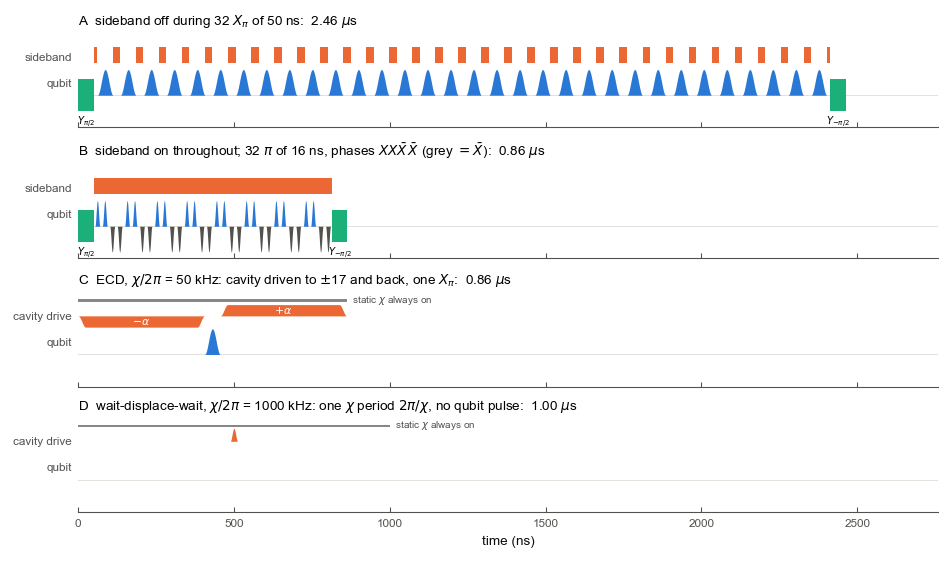

In [3]:
fig = cs.fig_sequences(sb, train, N_ECHO, GATE_NS, ecd, wait)
save(fig, "fig1_sequences"); plt.show()

---
## 2. Is the simulation right?
What is integrated, with no effective Hamiltonian anywhere:

* **A, B:** $H=\frac{\alpha}{2}n_q(n_q-1)+g(ab^\dagger+a^\dagger b)+\Omega_x(t)\frac{X}{2}+\Omega_y(t)\frac{Y}{2}$ (3-level transmon, sin² + DRAG pulses), the operators of `simulation.System`. Exact propagators: `expm` for the constant sideband pieces, `qutip.propagator` for the shaped pulses.
* **C:** $H=\frac{\alpha}{2}n_q(n_q-1)-a^\dagger a(\chi P_e+\chi_f P_f)+\frac{K}{2}a^{\dagger2}a^2+\varepsilon(t)a^\dagger+{\rm h.c.}+\Omega_x\frac X2+\Omega_y\frac Y2$, $K=-\chi^2/4|\alpha|$, $\chi_f=2\chi$, in the frame displaced by the drive's classical field $\alpha(t)$ (so 48 levels suffice for $\alpha_{\max}=17$). Excursion amplitude and a last small displacement come from the exact classical branch trajectories, as in a real ECD.
* **D:** the same static-$\chi$ Hamiltonian, not displaced (the field stays small): wait $\pi/\chi$, one displacement, wait $\pi/\chi$. Free evolution is the conditional rotation $R(\theta\sigma_z)=e^{i\theta a^\dagger a\sigma_z}$, $\theta=\chi t/2$, so $R(\tfrac\pi2\sigma_z)\,D(\alpha)\,R(\tfrac\pi2\sigma_z)=D(i\alpha\sigma_z)\,(-1)^{a^\dagger a}$: a CD times the cavity parity, and the parity is a cavity phase-reference update by $\pi$. (A single wait of $\pi/\chi$ only works on the vacuum: any other input is left conditionally rotated.)

Each line must be ~0: two independent integrators, the previous notebook's numbers, the frame change, the truncation.

In [4]:
rng = np.random.default_rng(7)
psi = np.zeros(3 * CUTOFF, complex)
psi[sb.inputs] = rng.normal(size=len(sb.inputs)) + 1j * rng.normal(size=len(sb.inputs))
psi /= np.linalg.norm(psi)                                   # random joint input, n <= NMAX_IN
old = pd.read_csv("results/noiseless_gate_fraction_scan.csv").set_index(["model", "cycles"]).gate_fidelity
small = cs.Chi(500, 2.0, BETA, RAMP_NS, GATE_NS, kerr=False)
w0 = cs.Wait(CHI_WAIT_KHZ, BETA, DISP_NS, kerr=False)
sb64 = cs.Sideband(3, 64, SWAP_NS, ALPHA_MHZ, "drag", DRAG, GATE_NS, NMAX_IN)
ecd64 = cs.Chi(CHI_KHZ, G_KHZ / CHI_KHZ, BETA, RAMP_NS, GATE_NS, cutoff=64)
inp64 = cs.input_indices(64, NMAX_IN)
checks = pd.DataFrame([
    ("A = previous notebook, ideal 2-level qubit (gate F)",
     ideal.F(ideal.echo(N_ECHO, GATE_NS, BETA), BETA) - old["Ideal 2-level rotations", N_ECHO // 2]),
    ("A = previous notebook, 3-level DRAG transmon (gate F)",
     sb.F(sb.echo(N_ECHO, GATE_NS, BETA), BETA) - old["3-level shaped rotations", N_ECHO // 2]),
    ("B: propagators vs one sesolve of H(t)  (1 - overlap)",
     1 - abs(np.vdot(U["B"] @ psi, sb.sesolve(train, psi))) ** 2),
    ("C: propagators vs one sesolve of H(t)  (1 - overlap)",
     1 - abs(np.vdot(U["C"] @ psi, ecd.sesolve(psi))) ** 2),
    ("C: displaced frame vs lab frame, chi = 500 kHz, 100 levels  (1 - overlap)",
     1 - abs(np.vdot(small.gate() @ psi, small.lab_frame(psi, 100))) ** 2),
    ("D: propagators vs one sesolve of H(t)  (1 - overlap)",
     1 - abs(np.vdot(U["D"] @ psi, wait.sesolve(psi))) ** 2),
    ("D with the Kerr term off: 1 - gate F after the parity frame",
     1 - cs.frame_correction(w0.gate(), w0.target, w0.inputs, 3, CUTOFF)[2]),
    ("B: cavity cutoff 48 -> 64 (gate F)",
     cs.gate_fidelity(sb64.gate(sb64.train("XX-XbarXbar", N_PI, TP_NS, BETA)), sb64.target(BETA), inp64) - sb.F(U["B"], BETA)),
    ("C: cavity cutoff 48 -> 64 (gate F)",
     cs.gate_fidelity(ecd64.gate(), ecd64.target, inp64) - cs.gate_fidelity(U["C"], ecd.target, ecd.inputs)),
], columns=["check", "difference"])
display(checks.style.format({"difference": "{:+.1e}"}).hide(axis="index"))
assert checks.difference.abs().max() < 1e-5

C:\Users\Inline6\anaconda3\envs\in6\Lib\site-packages\qutip\solver\integrator\scipy_integrator.py:80: SparseEfficiencyWarning: Constructing a DIA matrix with 144 diagonals is inefficient
  state0 = _data.column_stack(state0)


C:\Users\Inline6\anaconda3\envs\in6\Lib\site-packages\qutip\solver\integrator\scipy_integrator.py:80: SparseEfficiencyWarning: Constructing a DIA matrix with 192 diagonals is inefficient
  state0 = _data.column_stack(state0)


check,difference
"A = previous notebook, ideal 2-level qubit (gate F)",+8.1e-11
"A = previous notebook, 3-level DRAG transmon (gate F)",-1.2e-07
B: propagators vs one sesolve of H(t) (1 - overlap),-1.4e-11
C: propagators vs one sesolve of H(t) (1 - overlap),+1.8e-12
"C: displaced frame vs lab frame, chi = 500 kHz, 100 levels (1 - overlap)",+2.1e-11
D: propagators vs one sesolve of H(t) (1 - overlap),+9.1e-14
D with the Kerr term off: 1 - gate F after the parity frame,-3.0e-14
B: cavity cutoff 48 -> 64 (gate F),-2.2e-10
C: cavity cutoff 48 -> 64 (gate F),-3.4e-12


---
## 3. Is it really CD($\beta$)?
**Why B works.** For a two-level transmon, with $\sigma_y=-i(\sigma_+-\sigma_-)$,
$$g(a\sigma_++a^\dagger\sigma_-)=\tfrac g2(a+a^\dagger)\,\sigma_x+\tfrac g2\,i(a-a^\dagger)\,\sigma_y .$$
In the frame of the $x$-drive, $\theta(t)=\int\Omega_x$, the first half commutes with the drive and is untouched; the second rotates:
$$\tilde H(t)=\tfrac g2(a+a^\dagger)\sigma_x+\tfrac g2\,i(a-a^\dagger)\big[\sigma_y\cos\theta(t)-\sigma_z\sin\theta(t)\big].$$
If $\langle\cos\theta\rangle=\langle\sin\theta\rangle=0$ over the window $T$, the average is $\tfrac g2(a+a^\dagger)\sigma_x$, i.e. $D(-i\beta\sigma_x)$ with $\beta=gT/2$: **the pulses cost no force time**. $Y_{\mp\pi/2}$ turn $\sigma_x$ into $\sigma_z$. If also $\tilde H(T-t)=\tilde H(t)$, every even order of the Magnus expansion vanishes (section 4).

**The evidence**, on the 18-dimensional input space $P=\{g,e\}\otimes\{0..8\}$, for the calibrated gates:
* $W=P\,U_{\rm target}^\dagger U P$ must be the identity up to one global phase: $\|e^{-i\phi}W-1\|$, the spread of its eigenphases, its smallest singular value;
* the Heisenberg picture must give $U^\dagger aU=a-i\beta\sigma_z$: $\|\Delta a\|$, and $\langle U^\dagger aU\rangle$ from $|g,0\rangle$, $|e,0\rangle$ must be $+i\beta$, $-i\beta$;
* the Wigner functions must match the target for vacuum *and* for a Fock state (figure: B **bare**, no calibration).

,gate F bare,gate F,F |+>|0>,||W - 1||,eigenphase spread (deg),min sing. value,||U'aU - a + i b sz||,"from g,0","from e,0"
protocol,,,,,,,,,
A sideband echo,97.067%,99.497%,99.920%,0.091,8.869,0.993,0.149,-0.004000+2.013000j,0.002000-2.013000j
"B sideband on, $X X \bar X \bar X$",97.952%,99.318%,99.943%,0.134,14.988,0.990,0.163,0.004000+2.000000j,0.009000-2.000000j
"C static $\chi$, ECD",98.348%,99.918%,99.996%,0.042,3.873,0.999,0.075,0.002000+2.000000j,-0.002000-2.000000j
"D static $\chi$, wait-displace-wait",1.342%,99.097%,99.768%,0.152,15.771,0.995,0.223,0.047000+1.999000j,-0.047000-1.999000j


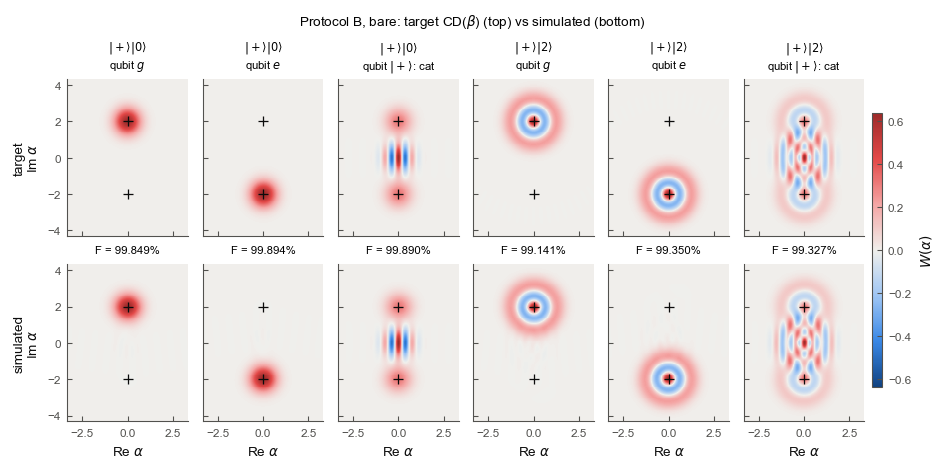

In [5]:
rows = []
for k in "ABCD":
    p = cs.proof(CAL[k]["U"], TARGET[k], sb.inputs, BETA, 3, CUTOFF)
    rows.append({"protocol": cs.PROT[k][0], "gate F bare": cs.gate_fidelity(U[k], TARGET[k], sb.inputs),
                 "gate F": CAL[k]["F"], "F |+>|0>": cs.state_fidelity(CAL[k]["U"], TARGET[k], cs.ket(3, CUTOFF)),
                 "||W - 1||": p["dist"], "eigenphase spread (deg)": np.degrees(p["eig_spread"]),
                 "min sing. value": p["sv_min"], "||U'aU - a + i b sz||": p["da"],
                 "<a> from g,0": np.round(p["beta_g"], 3), "<a> from e,0": np.round(p["beta_e"], 3)})
proof = pd.DataFrame(rows).set_index("protocol")
display(proof.style.format({c: "{:.3%}" for c in ["gate F bare", "gate F", "F |+>|0>"]} |
                           {c: "{:.3f}" for c in proof.columns[3:7]}))
fig, wig = cs.fig_proof(sb, U["B"], BETA, [(r"$|+\rangle|0\rangle$", 0), (r"$|+\rangle|2\rangle$", 2)])
fig.suptitle("Protocol B, bare: target CD($\\beta$) (top) vs simulated (bottom)", fontsize=7.5)
save(fig, "fig2_wigner"); plt.show()

**Linearity in $\beta$** (B bare; same pulse spacing and $t_p$, so the number of pulses grows with $T=2\beta/g$). The bare displacement falls ~1.4% short at $\beta=2$; the calibration knob (a 1.4% longer window) removes that.

C:\Users\Inline6\anaconda3\envs\in6\Lib\site-packages\qutip\solver\integrator\scipy_integrator.py:80: SparseEfficiencyWarning: Constructing a DIA matrix with 144 diagonals is inefficient
  state0 = _data.column_stack(state0)


,0,1,2,3,4,5,6
beta,0.2500,0.5000,1.0000,1.5000,2.0000,2.5000,3.0000
N,4.0000,8.0000,16.0000,24.0000,32.0000,40.0000,48.0000
F,0.9989,0.9985,0.9962,0.9906,0.9795,0.9595,0.9264
F_plus0,0.9996,0.9999,0.9995,0.9991,0.9982,0.9965,0.9932
beta_g,0.2477,0.4951,0.9894,1.4820,1.9722,2.4593,2.9424
beta_e,-0.2475,-0.4950,-0.9893,-1.4818,-1.9720,-2.4590,-2.9420


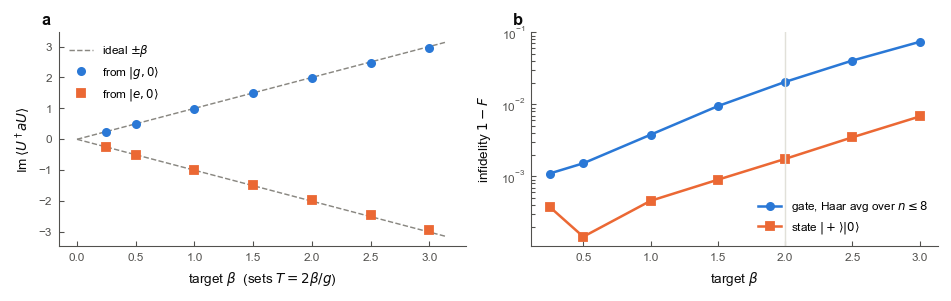

In [6]:
spacing = sb.T(BETA) / N_PI
rows = []
for b in BETA_SWEEP:
    N = 4 * max(1, round(sb.T(b) / (4 * spacing)))
    tr = sb.train("XX-XbarXbar", N, TP_NS, b)
    if not tr.fits:
        continue
    Ub = sb.gate(tr)
    p = cs.proof(Ub, sb.target(b), sb.inputs, b, 3, CUTOFF)
    rows.append(dict(beta=b, N=N, F=sb.F(Ub, b), F_plus0=cs.state_fidelity(Ub, sb.target(b), cs.ket(3, CUTOFF)),
                     beta_g=p["beta_g"].imag, beta_e=p["beta_e"].imag))
beta_df = pd.DataFrame(rows)
display(beta_df.round(4).T)
fig = cs.fig_beta(beta_df, BETA, DATA); save(fig, "fig3_beta"); plt.show()

---
## 4. Why the phases of the $\pi$ pulses decide everything
(a) $\sin\theta(t)$ multiplies the unwanted $\sigma_z\,i(a-a^\dagger)$ term. $\cos\theta$ is the same $\pm1$ square wave for all patterns and averages to zero. (b) Ideal two-level qubit, square pulses, bare: same-sense pulses stall at an error floor, alternating ones get *worse* with more pulses, the palindrome follows the zero-length-pulse limit (protocol A's Trotter error).

N,8,12,16,24,32,48,64,96,128
pattern,,,,,,,,,
X-Xbar,6.6e-01,2.4e-01,1.5e-01,2.7e-01,4.4e-01,7.1e-01,8.4e-01,nan,nan
XX,6.7e-01,3.7e-01,3.0e-01,2.7e-01,2.4e-01,1.9e-01,1.4e-01,nan,nan
XX-XbarXbar,6.6e-01,2.3e-01,8.5e-02,2.0e-02,8.3e-03,3.1e-03,1.7e-03,nan,nan
delta,6.6e-01,2.2e-01,7.3e-02,1.4e-02,4.4e-03,8.7e-04,2.7e-04,5.4e-05,1.7e-05
rotary,6.6e-01,2.4e-01,1.0e-01,5.2e-02,4.1e-02,3.1e-02,2.4e-02,nan,nan


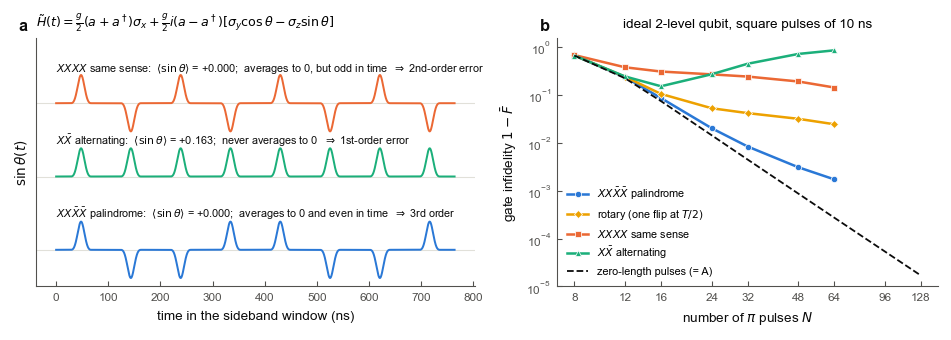

In [7]:
demo = {p: cs.toggling(sb.train(p, 8, 40, BETA)) for p in ["XX", "X-Xbar", "XX-XbarXbar"]}
rows = []
for N in N_SWEEP:
    for p in ["XX-XbarXbar", "rotary", "XX", "X-Xbar"]:
        if N % cs.PATTERNS[p][1] == 0:
            rows.append(dict(pattern=p, N=N, F=ideal.F(ideal.gate(ideal.train(p, N, TP_IDEAL, BETA)), BETA)))
    rows.append(dict(pattern="delta", N=N, F=ideal.F(ideal.gate(ideal.train("XX", N, 0, BETA)), BETA)))
why = pd.DataFrame(rows)
display(why.pivot(index="pattern", columns="N", values="F").map(lambda f: f"{1 - f:.1e}"))
fig = cs.fig_why(demo, why, TP_IDEAL); save(fig, "fig4_phases"); plt.show()

---
## 5. Fidelity versus the knobs (rate ratio, pulse rate, pulse length)
Fig 5, ideal qubit, bare. (a) Longer pulses at fixed $N$. (b) Back-to-back pulses are a continuous Rabi drive at $\Omega_R=\pi/t_p$: the palindrome falls as $(\Omega_R/g)^{-4}$, constant phase only as $(\Omega_R/g)^{-2}$ (that is the `driven` protocol of the previous notebook). (c) Halving $g$ and doubling $t_p$ gives the **same** gate: only the number of pulses $N$ and the duty cycle $Nt_p/T$ matter.

Fig 6, realistic transmon (3 levels, $\alpha/2\pi=-200$ MHz, sin² + DRAG), **calibrated** at every point. Grey: the pulses do not fit into $T$. Star: best point. Circle: the operating point used above.

swap_ns         300         600         1200
N   duty                                    
32  0.10  4.6219e-03  4.6219e-03  4.6219e-03
    0.25  5.6393e-03  5.6393e-03  5.6393e-03
    0.50  1.0359e-02  1.0359e-02  1.0359e-02
    0.75  2.0362e-02  2.0362e-02  2.0362e-02
    1.00  3.5502e-02  3.5502e-02  3.5502e-02
64  0.10  2.8450e-04  2.8450e-04  2.8450e-04
    0.25  3.5386e-04  3.5386e-04  3.5386e-04
    0.50  6.7972e-04  6.7972e-04  6.7972e-04
    0.75  1.3775e-03  1.3775e-03  1.3775e-03
    1.00  2.4384e-03  2.4384e-03  2.4384e-03
128 0.10  1.7703e-05  1.7703e-05  1.7703e-05
    0.25  2.2133e-05  2.2133e-05  2.2133e-05
    0.50  4.3010e-05  4.3010e-05  4.3010e-05
    0.75  8.7760e-05  8.7760e-05  8.7760e-05
    1.00  1.5569e-04  1.5569e-04  1.5569e-04

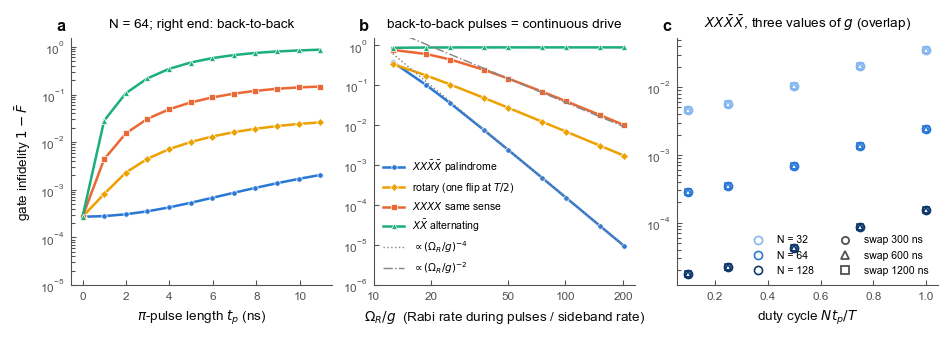

In [8]:
T0 = ideal.T(BETA)
bytp = pd.DataFrame([dict(pattern=p, tp_ns=tp, F=ideal.F(ideal.gate(ideal.train(p, N_TP, tp, BETA)), BETA))
                     for p in ["XX-XbarXbar", "rotary", "XX", "X-Xbar"]
                     for tp in np.linspace(0, 1000 * T0 / N_TP, 13).round(3)])
full = pd.DataFrame([dict(pattern=p, N=N, ratio=np.pi * N / (2 * BETA),
                          F=ideal.F(ideal.gate(ideal.train(p, N, 1000 * T0 / N, BETA)), BETA))
                     for p in ["XX-XbarXbar", "rotary", "XX", "X-Xbar"] for N in FULL_N])
rows = []
for sw in [300, 600, 1200]:
    m = cs.Sideband(2, CUTOFF, sw, shape="square", basis_ns=0, nmax_in=NMAX_IN)
    for N in [32, 64, 128]:
        for duty in [0.1, 0.25, 0.5, 0.75, 1.0]:
            rows.append(dict(swap_ns=sw, N=N, duty=duty,
                             F=m.F(m.gate(m.train("XX-XbarXbar", N, duty * 1000 * m.T(BETA) / N, BETA)), BETA)))
collapse = pd.DataFrame(rows)
display(collapse.pivot_table(index=["N", "duty"], columns="swap_ns", values="F").map(lambda f: f"{1 - f:.4e}"))
fig = cs.fig_sweeps(bytp, full, collapse, N_TP); save(fig, "fig5_sweeps"); plt.show()

swap 300 ns: best B = 0.23% at N = 48, t_p = 12 ns (knob 1.0208);  best A (N = 16, 32, 64) = 0.12%
swap 600 ns: best B = 0.06% at N = 64, t_p = 20 ns (knob 1.0098);  best A (N = 16, 32, 64) = 0.10%


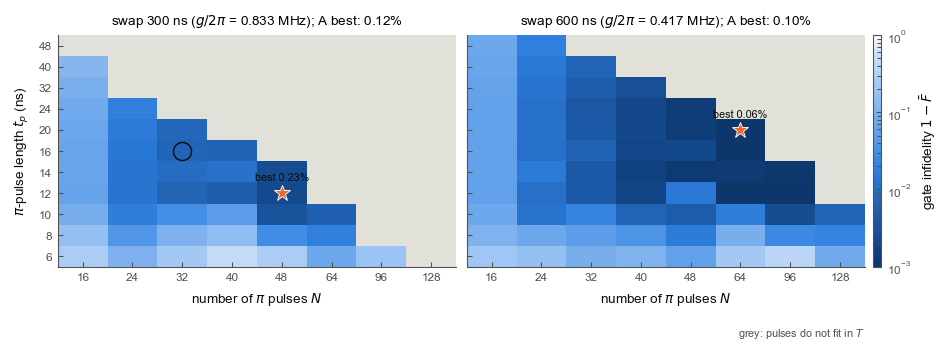

In [9]:
tasks = [dict(DEV, kind="continuous", swap_ns=sw, N=N, tp_ns=tp) for sw in MAP_SWAPS for N in MAP_N for tp in MAP_TP]
tasks += [dict(DEV, kind="echo", swap_ns=sw, N=N, tp_ns=GATE_NS) for sw in MAP_SWAPS for N in [16, 32, 64]]
with ProcessPoolExecutor(max_workers=WORKERS) as pool:
    mapped = pd.DataFrame(list(pool.map(cs.calibrated, tasks)))
maps = {sw: mapped[(mapped.kind == "continuous") & (mapped.swap_ns == sw)][["N", "tp_ns", "F", "scale"]]
        for sw in MAP_SWAPS}
echo_best = {sw: mapped[(mapped.kind == "echo") & (mapped.swap_ns == sw)].F.max() for sw in MAP_SWAPS}
for sw, df in maps.items():
    b = df.loc[df.F.idxmax()]
    print(f"swap {sw} ns: best B = {100 * (1 - b.F):.2f}% at N = {b.N:.0f}, t_p = {b.tp_ns:g} ns (knob {b.scale:.4f});"
          f"  best A (N = 16, 32, 64) = {100 * (1 - echo_best[sw]):.2f}%")
fig = cs.fig_map(maps, echo_best, head=(SWAP_NS, N_PI, TP_NS)); save(fig, "fig6_transmon_map"); plt.show()

---
## 6. Static $\chi$ (protocols C and D), no decoherence
(a) With a static $\chi$ the qubit frequency depends on the photon number: a $\pi$ pulse tuned to $n=0$ is **detuned by $\chi n$**. ECD (C) fires its one $\pi$ pulse with the cavity back near the origin, at the sideband's force rate $\chi\alpha_{\max}=g$, so weak $\chi$ needs a large excursion ($\alpha_{\max}=g/\chi=17$ at 50 kHz). Wait–displace–wait (D) needs **no qubit pulse**, so nothing is off resonance. Without Kerr it is exact (section 2); its error is the cavity Kerr that comes with $\chi$, here $K=\chi^2/4|\alpha|$. So D's error grows with $\chi$ while its duration $2\pi/\chi$ shrinks.

(b) All four, calibrated, no decoherence. Not modelled for C and D: the photon-number dependence of $\chi$ itself ($\chi'$).

,chi_khz,amp,scale,phi_q,phi_c,F,F_ideal_pi
0,10,83.33333,0.99998,0.05102,6.28620,0.99956,0.99957
1,20,41.66667,0.99998,0.10203,6.28621,0.99951,0.99957
2,50,16.66667,0.99999,0.25516,0.00308,0.99918,0.99957
3,100,8.33333,0.99999,0.51084,0.00330,0.99803,0.99957
4,200,4.16667,0.99999,1.02588,0.00415,0.99343,0.99954
5,500,1.66667,0.99992,2.64074,0.01016,0.96047,0.99909


,chi_khz,scale,phi_q,phi_c,F,gate_ns
12,250,0.99999,0.01558,-3.13180,0.99943,4000.0
13,500,0.99995,0.03116,3.16115,0.99773,2000.0
14,1000,0.99981,-6.22087,-3.10257,0.99097,1000.0
15,2000,0.99924,0.12452,-3.06405,0.96462,500.0
16,4000,0.99712,0.24827,3.29353,0.86848,250.0


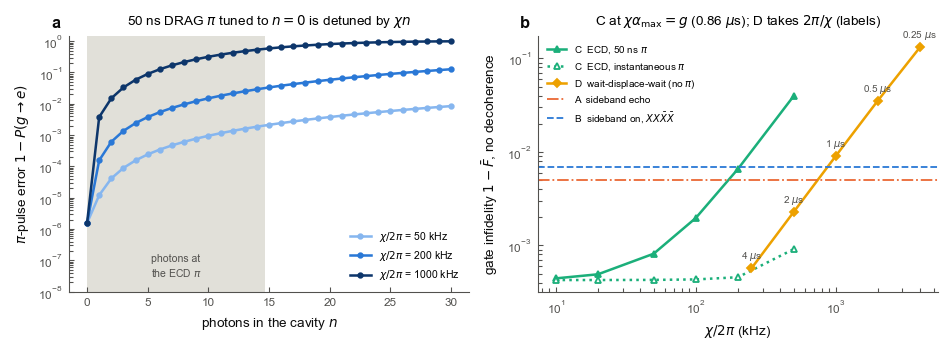

In [10]:
n_list = np.arange(0, 31)
flip = {chi: (n_list, cs.pi_flip_error(chi, n_list, GATE_NS, ALPHA_MHZ, DRAG)) for chi in [50, 200, 1000]}
tasks = [dict(DEV, kind="ecd", chi_khz=c, amp=G_KHZ / c, ramp_ns=RAMP_NS, tp_ns=tp) for c in CHI_SWEEP
         for tp in (GATE_NS, 0)] + [dict(DEV, kind="wait", chi_khz=c, disp_ns=DISP_NS) for c in WAIT_SWEEP]
with ProcessPoolExecutor(max_workers=WORKERS) as pool:
    swept = pd.DataFrame(list(pool.map(cs.calibrated, tasks)))
ecd_s = swept[swept.kind == "ecd"]
chi_df = ecd_s[ecd_s.tp_ns == GATE_NS][["chi_khz", "amp", "scale", "phi_q", "phi_c", "F"]].merge(
    ecd_s[ecd_s.tp_ns == 0][["chi_khz", "F"]].rename(columns={"F": "F_ideal_pi"}), on="chi_khz")
wait_df = swept[swept.kind == "wait"][["chi_khz", "scale", "phi_q", "phi_c", "F"]].copy()
wait_df["gate_ns"] = 1e6 / wait_df.chi_khz
display(chi_df.round(5), wait_df.round(5))
REF = {k: {"F": CAL[k]["F"]} for k in "AB"}
fig = cs.fig_chi(flip, chi_df, wait_df, REF, (0, (BETA / 2 + np.sqrt(NMAX_IN)) ** 2))
save(fig, "fig7_static_chi"); plt.show()

---
## 7. With decoherence
`qutip.mesolve` with the collapse operators of the previous notebook: $b/\sqrt{T_{1q}}$, $a/\sqrt{T_{1c}}$ and, for "T1 + Ramsey T2", $\sqrt{2/T_\phi}\,n$ for both, $1/T_\phi=1/T_2-1/2T_1$. Each protocol keeps its noiseless calibration.

For C the cavity dephasing acts on the *displaced* field, $n\to n+\alpha a^\dagger+\alpha^*a$, so during the excursion it is enhanced by $|\alpha|^2$. That is the **worst case for ECD**: white (Markovian) frequency noise is assumed here, as for every protocol. Slow frequency noise would largely be echoed away by the $\pm\alpha$ excursions, so read C's "T1 only" bar as its optimistic limit.

(a) C and D versus $\chi$, against A and B ($|+\rangle|0\rangle$). (b) The four operating points, $|+\rangle|0\rangle$, three noise conditions. (c) The gate fidelity averaged over the input space with T1 + T2: the exact noiseless average minus the decoherence loss averaged over random inputs (error bar: standard error).

A: mesolve(no noise) - propagator = +1.9e-10
B: mesolve(no noise) - propagator = -3.7e-08
C: mesolve(no noise) - propagator = -1.5e-06
D: mesolve(no noise) - propagator = -7.9e-08


noise,none,t1,t1_t2,wall_us
A sideband echo,99.920%,98.780%,98.319%,2.472
"B sideband on, $X X \bar X \bar X$",99.943%,99.534%,99.362%,0.875
"C static $\chi$, ECD",99.996%,99.616%,90.440%,0.862
"D static $\chi$, wait-displace-wait",99.768%,99.428%,99.181%,1.000


,F0,F,se
A sideband echo,99.497%,94.489%,0.208%
"B sideband on, $X X \bar X \bar X$",99.318%,97.481%,0.076%
"C static $\chi$, ECD",99.918%,60.806%,0.954%
"D static $\chi$, wait-displace-wait",99.097%,96.834%,0.094%


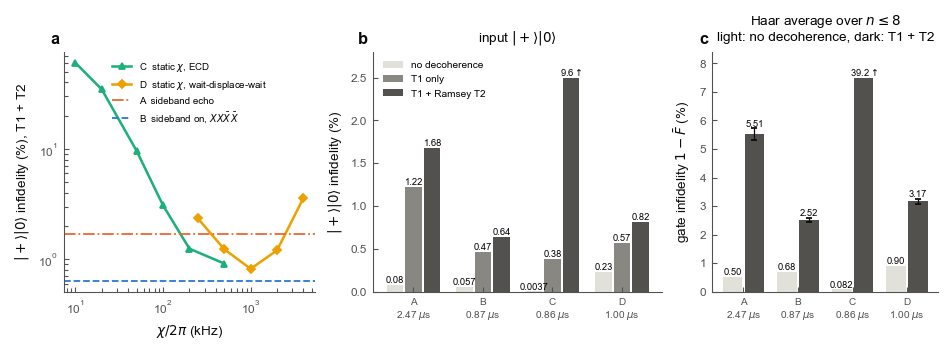

In [11]:
rng = np.random.default_rng(SEED)
psis = []
for _ in range(N_RANDOM):
    v = np.zeros(3 * CUTOFF, complex)
    v[sb.inputs] = rng.normal(size=len(sb.inputs)) + 1j * rng.normal(size=len(sb.inputs))
    psis.append(v / np.linalg.norm(v))
knob = lambda k: dict(scale=CAL[k]["scale"], phi_q=CAL[k]["phi_q"], phi_c=CAL[k]["phi_c"])
tasks = [dict(HEAD[k], **NOISE, **knob(k), protocol=k, noise=c) for k in "ABCD" for c in ["none", "t1", "t1_t2"]]
tasks += [dict(HEAD[k], **NOISE, **knob(k), protocol=k, noise="t1_t2", input=i, psi=v)
          for k in "ABCD" for i, v in enumerate(psis)]
tasks += [dict(DEV, **NOISE, kind="ecd", protocol="C sweep", chi_khz=r.chi_khz, amp=r.amp, ramp_ns=RAMP_NS,
               tp_ns=GATE_NS, noise="t1_t2", scale=r.scale, phi_q=r.phi_q, phi_c=r.phi_c) for r in chi_df.itertuples()]
tasks += [dict(DEV, **NOISE, kind="wait", protocol="D sweep", chi_khz=r.chi_khz, disp_ns=DISP_NS, noise="t1_t2",
               scale=r.scale, phi_q=r.phi_q, phi_c=r.phi_c) for r in wait_df.itertuples()]
with ProcessPoolExecutor(max_workers=WORKERS) as pool:
    noisy = pd.DataFrame(list(pool.map(cs.noisy_run, tasks)))
noisy.to_csv("results/continuous_sideband/noisy.csv", index=False)

head = noisy[noisy.protocol.isin(list("ABCD")) & noisy.input.isna()]
plus0 = head.pivot(index="protocol", columns="noise", values="F").reindex(list("ABCD"))
plus0["wall_us"] = head.groupby("protocol").wall_us.first()
for k in "ABCD":      # mesolve without noise must reproduce the propagators
    print(f"{k}: mesolve(no noise) - propagator = "
          f"{plus0.loc[k, 'none'] - cs.state_fidelity(CAL[k]['U'], TARGET[k], cs.ket(3, CUTOFF)):+.1e}")
rows = []
for k in "ABCD":
    r = noisy[(noisy.protocol == k) & noisy.input.notna()].sort_values("input")
    loss = np.array([cs.state_fidelity(CAL[k]["U"], TARGET[k], psis[int(i)]) for i in r.input]) - r.F.values
    rows.append(dict(protocol=k, F0=CAL[k]["F"], F=CAL[k]["F"] - loss.mean(), se=loss.std(ddof=1) / np.sqrt(len(loss))))
gavg = pd.DataFrame(rows).set_index("protocol")
REF = {k: {"F_noisy": plus0.loc[k, "t1_t2"]} for k in "AB"}
plus0.index = [cs.PROT[k][0] for k in plus0.index]
gavg.index = plus0.index
display(plus0.style.format({c: "{:.3%}" for c in ["none", "t1", "t1_t2"]} | {"wall_us": "{:.3f}"}),
        gavg.style.format({"F0": "{:.3%}", "F": "{:.3%}", "se": "{:.3%}"}))
fig = cs.fig_noise(noisy[noisy.protocol == "C sweep"], noisy[noisy.protocol == "D sweep"], plus0, gavg, REF,
                   data=DATA)
save(fig, "fig8_decoherence"); plt.show()

---
## 8. Robustness of B (realistic transmon)
(a) The error grows with the photon number in the input, as $g\sqrt n$ sets the averaging error. (b) A $\pi$-pulse amplitude error cancels inside every $X X\bar X\bar X$ block; same-sense pulses accumulate it. (c) A qubit detuning while the sideband is on (an uncorrected pump Stark shift) hardly matters. In (b, c) the knob stays at its nominal calibration: these are drifts.

C:\Users\Inline6\anaconda3\envs\in6\Lib\site-packages\qutip\solver\integrator\scipy_integrator.py:80: SparseEfficiencyWarning: Constructing a DIA matrix with 144 diagonals is inefficient
  state0 = _data.column_stack(state0)


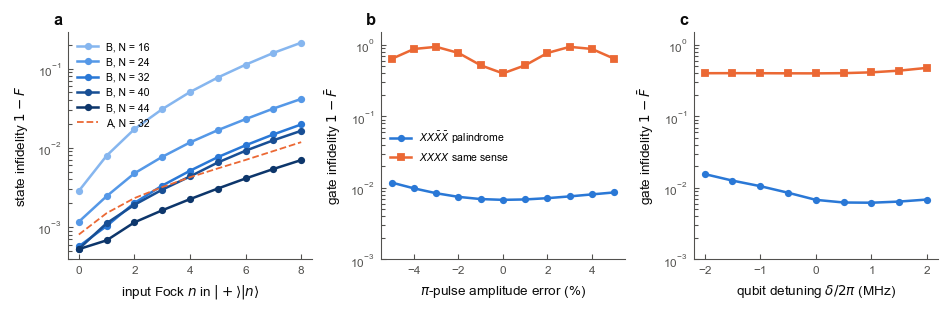

In [12]:
rows = []
for N in [16, 24, 32, 40, 44]:
    build, tgt, _ = cs.model(dict(DEV, kind="continuous", N=N, tp_ns=TP_NS))
    c = cs.calibrate(build, tgt, sb.inputs, 3, CUTOFF)
    Ub = cs.frame_diag(3, CUTOFF, c["phi_q"], c["phi_c"])[:, None] * c["U"]
    rows += [dict(kind="B", N=N, n=n, F=cs.state_fidelity(Ub, tgt, cs.ket(3, CUTOFF, (1, 1), n)))
             for n in range(NMAX_IN + 1)]
rows += [dict(kind="A", N=N_ECHO, n=n, F=cs.state_fidelity(CAL["A"]["U"], TARGET["A"], cs.ket(3, CUTOFF, (1, 1), n)))
         for n in range(NMAX_IN + 1)]
photon = pd.DataFrame(rows)
nominal = {"XX-XbarXbar": CAL["B"]}
build, tgt, _ = cs.model(dict(DEV, kind="continuous", N=N_PI, tp_ns=TP_NS, pattern="XX"))
nominal["XX"] = cs.calibrate(build, tgt, sb.inputs, 3, CUTOFF)

def drifted(m, p):
    k = nominal[p]
    Ud = cs.frame_diag(3, CUTOFF, k["phi_q"], k["phi_c"])[:, None] * m.gate(m.train(p, N_PI, TP_NS, BETA, k["scale"]))
    return cs.gate_fidelity(Ud, sb.target(BETA), sb.inputs)
amp = pd.DataFrame([dict(pattern=p, eps=e, F=drifted(m, p)) for e in np.linspace(-0.05, 0.05, 11)
                    for m in [cs.Sideband(3, CUTOFF, SWAP_NS, ALPHA_MHZ, "drag", DRAG, GATE_NS, NMAX_IN, amp_error=e)]
                    for p in ["XX-XbarXbar", "XX"]])
det = pd.DataFrame([dict(pattern=p, det_mhz=d, F=drifted(m, p)) for d in np.linspace(-2, 2, 9)
                    for m in [cs.Sideband(3, CUTOFF, SWAP_NS, ALPHA_MHZ, "drag", DRAG, GATE_NS, NMAX_IN, detuning_mhz=d)]
                    for p in ["XX-XbarXbar", "XX"]])
fig = cs.fig_robust(photon, amp, det, N_ECHO); save(fig, "fig9_robustness"); plt.show()

---
## 9. Summary (calibrated, $\beta=2$)

In [13]:
summary = pd.DataFrame({"gate time (us)": plus0.wall_us, "knob": [CAL[k]["scale"] for k in "ABCD"],
                        "gate F, no noise": gavg.F0, "gate F, T1+T2": gavg.F, "+- (SE)": gavg.se,
                        "|+>|0>, no noise": plus0["none"], "|+>|0>, T1": plus0["t1"], "|+>|0>, T1+T2": plus0["t1_t2"]})
summary.to_csv("results/continuous_sideband/summary.csv")
display(summary.style.format({"gate time (us)": "{:.3f}", "knob": "{:.4f}"} |
                             {c: "{:.2%}" for c in summary.columns[2:]}))
print(f"runtime {(time.perf_counter() - started) / 60:.1f} min")

,gate time (us),knob,"gate F, no noise","gate F, T1+T2",+- (SE),"|+>|0>, no noise","|+>|0>, T1","|+>|0>, T1+T2"
A sideband echo,2.472,1.0111,99.50%,94.49%,0.21%,99.92%,98.78%,98.32%
"B sideband on, $X X \bar X \bar X$",0.875,1.0144,99.32%,97.48%,0.08%,99.94%,99.53%,99.36%
"C static $\chi$, ECD",0.862,1.0000,99.92%,60.81%,0.95%,100.00%,99.62%,90.44%
"D static $\chi$, wait-displace-wait",1.000,0.9998,99.10%,96.83%,0.09%,99.77%,99.43%,99.18%


runtime 14.2 min


---
## 10. Continuous $x$ drive with sign flips instead of a $\pi$ train? (device numbers)
Idea (2026-10-17): keep the qubit drive on the whole window, $+x$ for $2\pi$, then $-x$ for $2\pi$, ... A constant
$x$ drive commutes with $\tfrac g2(a+a^\dagger)\sigma_x$ and averages the $\sigma_y$ half away, and the flips cancel
the net rotation, so it is the continuous limit of $XX\bar X\bar X$. The device train is already almost that:
81 ns pulses with 2-9 ns gaps. Compared at the same peak Rabi frequency, 3-level transmon ($\alpha/2\pi=-153$ MHz),
$k=7.55\times10^5$ /s, 1.25 ns DAC samples, no decoherence, each point calibrated:

| shape | drive |
|---|---|
| **pulsed** | the device train: hann $\pi$ pulses, 10 ns edges, packed ($N=4K$ largest with $T/N\ge t_\pi$) |
| **hard** | flat drive, sign flips in one DAC sample (and abrupt on / off) |
| **smooth 10 ns** | flat drive, each flip passes through zero on a 10 ns cosine |
| **joined 10 ns** | $XX$ merged into one flat $2\pi$ block, hann edges (10 ns) only at the flips |
| **none** | flat $+x$, no flips |


In [ ]:
# ── 10. CD drive shapes: pi train vs continuous x drive (3-level transmon, DEVICE numbers) ─────────────
# Self-contained (numpy / scipy only). Q1C1 numbers: alpha -153 MHz, k = 7.55e5 /s (g/2pi = 240 kHz),
# hann pi with 10 ns edges, 1.25 ns DAC samples.
# H (frame of the qubit drive, sideband resonant on |e,n> <-> |g,n+1>):
#   H = alpha |f><f| + delta_d b^dag b + g (a b^dag + a^dag b) + Omega(t)/2 (b + b^dag),  Omega real, signed
# Target: |+><+| D(beta) + |-><-| D(-beta) on {g,e} x {0..N_IN}, times a qubit z frame and a cavity rotation.
# Calibrated per point: beta (complex), phi_q, phi_c, drive detune delta_d (f-level Stark shift).
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")           # one thread per worker process
import numpy as np
from scipy.linalg import expm
from scipy.optimize import minimize, minimize_scalar

TWO_PI = 2 * np.pi
DT = 1.25e-9                      # DAC sample (800 MS/s)
ALPHA = TWO_PI * -153e6           # Q1 anharmonicity (q1 R_x_180_ef detune -152.7 MHz)
K_CD = 7.55e5                     # measured CD rate beta / T [1/s]  (cd_beta_per_s)
G_SB = 2 * K_CD                   # sideband coupling g = 2k  (g/2pi = 240 kHz)
EDGE = 10e-9                      # hann edge of the device pi pulse (ramp 20 ns = 2 x 10 ns)
NQ, NC, N_IN = 3, 40, 4           # transmon levels, cavity cutoff, inputs {g,e} x {0..N_IN}


def ops(nc=NC):
    a = np.diag(np.sqrt(np.arange(1, nc)), 1)
    b = np.diag(np.sqrt(np.arange(1, NQ)), 1)
    Iq, Ic = np.eye(NQ), np.eye(nc)
    A, B = np.kron(Iq, a), np.kron(b, Ic)
    Pf = np.kron(np.diag([0, 0, 1.0]), Ic)
    return A, B, Pf


A, B, PF = ops()
NB = B.conj().T @ B
H_SB = G_SB * (A @ B.conj().T + A.conj().T @ B)
H_X = 0.5 * (B + B.conj().T)


def envelope(kind, T, omega_peak, flip_ns=5.0):
    """Signed Omega(t) [rad/s] on the DAC grid for a window T. All kinds rotate by pi per segment and
    flip sign every two segments (X X Xbar Xbar), except 'none' (constant +x, 2 pi per 2 segments)."""
    n_s = int(round(T / DT))
    t = (np.arange(n_s) + 0.5) * DT
    T = n_s * DT
    w = flip_ns * 1e-9
    if kind == "pulsed":
        t_pi = np.pi / omega_peak + EDGE              # hann flat-top: area = peak (flat + edge)
    elif kind == "joined":
        t_pi = np.pi / omega_peak + w / 2             # one edge of width w per pi on average (two per 2 pi block)
    else:
        t_pi = np.pi / omega_peak
    N = 4 * int(T / (4 * t_pi))
    if N < 4:
        return None
    seg = T / N
    k = np.minimum((t // seg).astype(int), N - 1)
    sign = np.where((k // 2) % 2 == 0, 1.0, -1.0)
    if kind == "none":
        sign[:] = 1.0
    if kind == "joined":
        blk = 2 * seg                                  # one block = two pi segments of the same sign
        x = t - (k // 2) * blk                         # time inside the block, 0..blk
        env = np.where(x < w, 0.5 * (1 - np.cos(np.pi * x / w)),
                       np.where(x > blk - w, 0.5 * (1 - np.cos(np.pi * (blk - x) / w)), 1.0))
        om = env * sign
        return om * (np.pi * N / (np.sum(np.abs(om)) * DT))      # area 2 pi per block
    if kind == "pulsed":
        flat = np.pi / omega_peak - EDGE
        tp = flat + 2 * EDGE
        x = t - (k + 0.5) * seg + tp / 2          # time inside pulse k, 0..tp
        env = np.where((x < 0) | (x > tp), 0.0,
                       np.where(x < EDGE, 0.5 * (1 - np.cos(np.pi * x / EDGE)),
                                np.where(x > tp - EDGE, 0.5 * (1 - np.cos(np.pi * (tp - x) / EDGE)), 1.0)))
        om = omega_peak * env * sign
    else:
        s = sign.copy()
        if kind == "smooth":
            # every sign change (and the switch-on / off) passes through zero on a cosine of flip_ns
            edges = np.unique(np.round(np.concatenate([[0.0, T], seg * (np.flatnonzero(np.diff(sign)) + 1)]) / DT) * DT)
            d = np.min(np.abs(t[:, None] - edges[None, :]), axis=1)
            s = sign * np.where(d < w / 2, np.sin(np.pi * d / w), 1.0)
        om = s * 1.0
        # area pi per segment: scale the amplitude (<= omega_peak by construction of N)
        om = om * (np.pi * N / (np.sum(np.abs(om)) * DT))
    return om


def propagate(om, delta_d):
    H0 = ALPHA * PF + delta_d * NB + H_SB
    U = np.eye(H0.shape[0], dtype=complex)
    cache = {}
    # run-length compress the piecewise-constant samples
    q = np.round(om, 3)
    change = np.flatnonzero(np.diff(q)) + 1
    starts = np.concatenate([[0], change]); ends = np.concatenate([change, [len(q)]])
    for s0, s1 in zip(starts, ends):
        key = (q[s0], s1 - s0)
        if key not in cache:
            cache[key] = expm(-1j * (H0 + q[s0] * H_X) * DT * (s1 - s0))
        U = cache[key] @ U
    return U


def idx(q, n):
    return q * NC + n


INPUTS = [idx(q, n) for q in (0, 1) for n in range(N_IN + 1)]
a_c = np.diag(np.sqrt(np.arange(1, NC)), 1)
# D(r e^{i th}) = R(th) D(r) R(th)^dag with D(r) = exp(r (a^dag - a)) = exp(i r P), P = -i (a^dag - a) Hermitian
_lam, _vec = np.linalg.eigh(-1j * (a_c.conj().T - a_c))
_n = np.arange(NC)


def displacement(z):
    r, th = abs(z), np.angle(z)
    Dr = (_vec * np.exp(1j * r * _lam)) @ _vec.conj().T
    ph = np.exp(1j * th * _n)
    return ph[:, None] * Dr * ph.conj()[None, :]


def target(beta, phi_q, phi_c):
    D = displacement
    plus = np.array([1, 1, 0]) / np.sqrt(2); minus = np.array([1, -1, 0]) / np.sqrt(2)
    V = np.kron(np.outer(plus, plus), D(beta)) + np.kron(np.outer(minus, minus), D(-beta))
    frame = np.kron(np.diag([np.exp(-0.5j * phi_q), np.exp(0.5j * phi_q), 1]), np.diag(np.exp(-1j * phi_c * np.arange(NC))))
    return frame @ V


def fidelity(U, beta, phi_q, phi_c):
    V = target(beta, phi_q, phi_c)
    M = V[:, INPUTS].conj().T @ U[:, INPUTS]
    d = len(INPUTS)
    return float((np.trace(M @ M.conj().T).real + abs(np.trace(M)) ** 2) / (d * (d + 1)))


def best_frame(U, beta0):
    f = lambda p: -fidelity(U, p[0] + 1j * p[1], p[2], p[3])
    best = None
    for pq in (0.0, np.pi / 2, np.pi, -np.pi / 2):
        r = minimize(f, [beta0.real, beta0.imag, pq, 0.0], method="Nelder-Mead",
                     options=dict(xatol=1e-5, fatol=1e-8, maxiter=4000))
        if best is None or r.fun < best.fun:
            best = r
    return -best.fun, best.x


def beta_guess(U):
    psi = U[:, idx(0, 0)] + U[:, idx(1, 0)]          # |+>|0>
    psi /= np.linalg.norm(psi)
    return complex(psi.conj() @ (A @ psi))


def leakage(U):
    return float(np.mean([np.real(U[:, i].conj() @ PF @ U[:, i]) for i in INPUTS]))


def run(kind, beta, omega_peak, flip_ns=5.0, calibrate_detune=True):
    """One calibrated point. kind: pulsed (device hann pi train), hard (flat drive, sign flips in one
    sample), smooth (flat drive, flips through zero on a cosine of flip_ns), joined (flat 2 pi blocks with hann
    edges of flip_ns only at the flips), none (flat +x drive, no flips)."""
    T = beta / K_CD
    om = envelope(kind, T, omega_peak, flip_ns)
    if om is None:
        return None
    def score(dd):
        U = propagate(om, dd)
        return best_frame(U, beta_guess(U))[0], U
    if calibrate_detune:
        grid = TWO_PI * np.linspace(-1.5e6, 1.5e6, 31)
        coarse = [score(dd)[0] for dd in grid]
        i = int(np.argmax(coarse))
        lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]
        r = minimize_scalar(lambda dd: -score(dd)[0], bounds=(lo, hi), method="bounded",
                            options=dict(xatol=TWO_PI * 1e3))
        dd = r.x
    else:
        dd = 0.0
    F, U = score(dd)
    return dict(kind=kind if kind in ("pulsed", "hard", "none") else f"{kind} {flip_ns:g} ns", beta=beta, f_peak_mhz=omega_peak / TWO_PI / 1e6, F=F, err=1 - F, leak=leakage(U),
                detune_khz=dd / TWO_PI / 1e3, n_pi=int(round(np.sum(np.abs(om)) * DT / np.pi)),
                f_avg_mhz=np.mean(np.abs(om)) / TWO_PI / 1e6)


In [ ]:
from concurrent.futures import ProcessPoolExecutor
import pandas as pd, matplotlib.pyplot as plt

DRIVE_SHAPES = [("pulsed", 0), ("hard", 0), ("smooth", 10), ("joined", 10), ("none", 0)]
F_PEAK_MHZ   = [3, 5, 7.05, 10, 14, 20]          # 7.05 MHz = R_x_180_cd (ramp 20 ns, flat 60.9 ns)
tasks = [(k, b, TWO_PI * f * 1e6, fl) for b in (1.0, 2.0) for f in F_PEAK_MHZ for k, fl in DRIVE_SHAPES]
with ProcessPoolExecutor(max_workers=min(28, os.cpu_count())) as pool:     # ~3 min on 32 cores
    shapes = pd.DataFrame([x for x in pool.map(run, *zip(*tasks)) if x])
os.makedirs("results/continuous_sideband", exist_ok=True)
shapes.to_csv("results/continuous_sideband/drive_shapes.csv", index=False)

# why smoothing the flips fails: averaging needs <cos theta> = <sin theta> = 0, theta = int Omega dt
theta_avg = pd.DataFrame([dict(shape=f"{k} {fl} ns" if fl else k,
                               cos=np.mean(np.cos(np.cumsum(om) * DT)), sin=np.mean(np.sin(np.cumsum(om) * DT)))
                          for k, fl in DRIVE_SHAPES[:4] + [("joined", 2.5)]
                          for om in [envelope(k, 2.0 / K_CD, TWO_PI * 7.05e6, fl)]]).set_index("shape")
display(theta_avg.round(4))

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for c, b in enumerate((1.0, 2.0)):
    for name, sub in shapes[shapes.beta == b].groupby("kind"):
        sub = sub.sort_values("f_peak_mhz")
        axs[0, c].semilogy(sub.f_peak_mhz, sub.err, "o-", label=name)
        axs[1, c].semilogy(sub.f_peak_mhz, sub.leak, "o-", label=name)
    axs[0, c].set_title(f"beta = {b:g}  (T = {b / K_CD * 1e6:.2f} us)")
    for r in (0, 1):
        axs[r, c].axvline(7.05, color="grey", ls=":")
    axs[1, c].set_xlabel("peak Rabi frequency (MHz)")
axs[0, 0].set_ylabel("gate error (calibrated)"); axs[1, 0].set_ylabel("population left in f")
axs[0, 1].legend(fontsize=8)
fig.tight_layout(); save(fig, "fig10_drive_shapes") if "save" in globals() else None; plt.show()


**Result** ($\beta=2$, gate error / population left in $f$):

| peak Rabi | pulsed (device) | hard flips | smooth 10 ns | joined 10 ns | no flips |
|---|---|---|---|---|---|
| 7.05 MHz (device $\pi$) | 0.71 % / 2e-5 | 0.97 % / 2.2e-3 | 0.91 % / 1.3e-3 | 5.7 % / 2e-5 | 23 % |
| 10 MHz | 0.20 % / 4e-5 | 1.3 % / 8.8e-3 | 1.3 % / 8.4e-3 | 8.5 % / 2e-5 | 15 % |
| 14 MHz | **0.058 %** / 2e-5 | 0.97 % / 6.9e-3 | 4.5 % / 7.6e-3 | 13 % / 2e-5 | 17 % |
| 20 MHz | **0.021 %** / 5e-5 | 7.1 % / 5.4e-2 | 18 % / 6.7e-2 | 22 % / 5e-5 | 28 % |

* **Flips fast compared with $1/|\alpha|\approx6.5$ ns leak** (hard; smooth 10 ns, whose cosine reaches full drive 5 ns from the zero crossing): the drive dresses $|e\rangle$ with $\sim(\Omega/\alpha)^2$ of $|f\rangle$,
  and a fast switch leaves it there. Ziqian's point: the drive must ramp through zero slowly ($\gtrsim$ 10 ns each side).
* **Ramping only at the flips breaks the averaging** (joined): the rotation angle $\theta$ lingers on every ramp, and
  the joined drive lingers only at $\theta=0$, so $\langle\cos\theta\rangle=+0.06$ (pulsed and hard: 0.0000) and the
  $\sigma_y\,i(a-a^\dagger)$ half no longer averages away. Two-level limit, same thing: joined 5.7 %, pulsed 0.73 %.
* **The pulsed train is already the right continuous drive:** its ramps between $X$ and $X$ (at $\theta=\pi$) balance the
  ramps at the flips (at $\theta=0$), so it is slow at every switch *and* keeps $\langle\cos\theta\rangle=0$.
* **What helps is a faster $\pi$:** the averaging error falls steeply with the peak Rabi rate (0.71 % → 0.06 % going
  7 → 14 MHz at $\beta=2$), with leakage still $\sim$2e-5 (no DRAG). At 14 MHz the $\pi$ is 10 + 25.7 + 10 = 45.7 ns.
